### scikit-learn 1: Grundlagen - Übungen

**scikit-learn** (kurz `sklearn`) ist das bekannteste Python-Paket für **maschinelles Lernen**: Der Computer lernt aus Beispielen,
z. B. aus vielen vermessenen Blüten, zu welcher Art eine neue Blüte gehört. Niemand schreibt dafür Regeln von Hand.
Dieses Notebook zeigt das Grundmuster, das bei allen Verfahren gleich ist, und wie man prüft, wie gut ein Modell ist.

Die Reihe hat vier Notebooks:

1. **Grundlagen**: Merkmale und Zielwerte, das erste Modell, Trainings- und Testdaten, Skalieren (dieses Notebook)
2. Klassifikation: k-nächste Nachbarn, Entscheidungsbäume, logistische Regression, neuronale Netze, Kreuzvalidierung
3. Regression: Zahlen vorhersagen, Überanpassung
4. Unüberwachtes Lernen: Clustering, Dimensionen reduzieren, Ziffernerkennung

Vorausgesetzt werden *numpy: Grundlagen* und *matplotlib: Grundlagen*. Die Daten stehen in pandas-Tabellen; was du davon brauchst,
wiederholt der erste Abschnitt. Wer die pandas-Notebooks kennt, kann ihn überspringen.

**Tabellen anzeigen:** Steht eine Tabelle (ein DataFrame) in der **letzten Zeile** einer Zelle, zeigt JupyterLab sie als Tabelle an. Mehrere Tabellen
in einer Zelle zeigt man mit `display(df)` an. Einzelne Werte gibt man wie gewohnt mit `print()` aus. Die erwarteten Ausgaben in den Aufgaben sehen genauso aus.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import sklearn` lädt der Browser die Pakete nach. Das dauert einige Sekunden.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Beispieldaten anlegen

**Führe diese Zelle zuerst aus.** Sie legt zwei Dateien an:

- `iris.csv`: die berühmten Iris-Daten von 1936, 150 vermessene Schwertlilien von drei Arten (*setosa*, *versicolor*, *virginica*).
  Gemessen sind Länge und Breite des **Kelchblatts** und des **Blütenblatts** in cm.
- `obst.csv`: ausgedachte Daten von 48 Äpfeln und Birnen mit dem Gewicht in g und dem Verhältnis von Höhe zu Breite.

Die erste Zeile blendet eine harmlose Meldung aus, die das Python im Browser sonst beim ersten Training anzeigt.

In [ ]:
import warnings
warnings.filterwarnings('ignore', message='JsProxy')   # harmlose Meldung des Browser-Pythons ausblenden

from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame
iris.columns = ['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite', 'art']
iris['art'] = iris['art'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
iris.to_csv('iris.csv', index=False)

obst = '''gewicht,verhaeltnis,sorte
230,1.2,Birne
165,0.96,Apfel
190,1.21,Birne
135,1.15,Birne
193,0.98,Apfel
198,0.97,Apfel
166,1.23,Birne
194,1.26,Birne
211,1.22,Birne
204,1.31,Birne
141,1.22,Birne
151,1.13,Birne
150,0.96,Apfel
159,1.22,Birne
169,0.96,Apfel
206,1.29,Birne
214,1.22,Birne
205,1.18,Birne
207,1.0,Apfel
204,0.9,Apfel
203,1.25,Birne
141,0.98,Apfel
147,1.12,Birne
111,0.97,Apfel
175,1.26,Birne
184,0.9,Apfel
196,0.99,Apfel
175,1.3,Birne
177,1.29,Birne
196,0.91,Apfel
209,1.29,Birne
171,1.3,Birne
164,0.96,Apfel
187,1.29,Birne
174,1.08,Apfel
161,0.93,Apfel
179,1.24,Birne
139,0.93,Apfel
181,0.99,Apfel
179,0.92,Apfel
144,0.99,Apfel
131,0.98,Apfel
193,1.02,Apfel
144,0.9,Apfel
169,0.92,Apfel
172,0.94,Apfel
171,1.24,Birne
175,1.29,Birne
'''
with open('obst.csv', 'w', encoding='utf-8') as f:
    f.write(obst)
print('Angelegt: iris.csv, obst.csv')

## 1. pandas zum Auffrischen

#### Eine Tabelle einlesen

`pd.read_csv('datei.csv')` liest eine CSV-Datei in einen **DataFrame**, eine Tabelle mit benannten Spalten. Jede Zeile ist ein **Datensatz**
(hier: eine Blüte).

- `df.head(n)` zeigt die ersten `n` Zeilen (ohne Angabe 5).
- `df.shape` ist ein Tupel (Anzahl Zeilen, Anzahl Spalten), `len(df)` die Anzahl der Zeilen.
- `df.columns` sind die Spaltennamen, `list(df.columns)` macht daraus eine Liste.

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
print(iris.shape)
print(list(iris.columns))
iris.head()

#### Spalten und Kennzahlen

- `df['spalte']` ist **eine** Spalte (eine *Series*), `df[['a', 'b']]` mit **doppelten** Klammern ist eine Tabelle mit diesen Spalten.
- `df['spalte'].mean()`, `.min()`, `.max()` berechnen Kennzahlen einer Spalte.
- `df.describe()` zeigt die wichtigsten Kennzahlen aller Zahlenspalten.
- `df['spalte'].value_counts()` zählt, wie oft jeder Wert vorkommt. Bei gleichen Anzahlen ist die Reihenfolge nicht festgelegt;
  `.sort_index()` sortiert das Ergebnis nach den Werten (alphabetisch).

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
print(iris['bluete_laenge'].mean())
print(iris['art'].value_counts().sort_index())
iris[['bluete_laenge', 'bluete_breite']].describe()

#### Zeilen auswählen und Gruppen vergleichen

- `df[df['spalte'] > 5]` wählt die Zeilen aus, für die die Bedingung gilt. Mehrere Bedingungen verbindet man mit `&` (und) bzw. `|` (oder),
  jede in Klammern: `df[(df['a'] > 1) & (df['b'] == 'x')]`.
- `df.groupby('art').mean()` berechnet die Mittelwerte jeder Spalte getrennt für jede Art.

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
gross = iris[iris['bluete_laenge'] > 6.5]
print(len(gross))
display(gross)
iris.groupby('art').mean()

#### Aufgabe 1.1

Lies `obst.csv` ein, gib die Form der Tabelle und die Spaltennamen als Liste aus und zeige die ersten 3 Zeilen an.

**Erwartete Ausgabe:**

```
(48, 3)
['gewicht', 'verhaeltnis', 'sorte']
```

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">gewicht</th>
      <th style="text-align: right">verhaeltnis</th>
      <th style="text-align: right">sorte</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">230</td>
      <td style="text-align: right">1.20</td>
      <td style="text-align: right">Birne</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">165</td>
      <td style="text-align: right">0.96</td>
      <td style="text-align: right">Apfel</td>
    </tr>
    <tr>
      <th style="text-align: right">2</th>
      <td style="text-align: right">190</td>
      <td style="text-align: right">1.21</td>
      <td style="text-align: right">Birne</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
obst = pd.read_csv('obst.csv')
print(obst.shape)
print(list(obst.columns))
obst.head(3)
```

</details>

#### Aufgabe 1.2

Gib aus, wie viele Äpfel und wie viele Birnen in der Tabelle stehen (alphabetisch sortiert).

**Erwartete Ausgabe:**

```
sorte
Apfel    24
Birne    24
Name: count, dtype: int64
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
print(obst['sorte'].value_counts().sort_index())
```

</details>

#### Aufgabe 1.3

Gib das kleinste, das größte und das mittlere Gewicht aus (das mittlere mit einer Nachkommastelle).

**Erwartete Ausgabe:**

```
111
230
175.8
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
print(obst['gewicht'].min())
print(obst['gewicht'].max())
print(f"{obst['gewicht'].mean():.1f}")
```

</details>

#### Aufgabe 1.4

Zeige die Kennzahlen (`describe()`) der beiden Zahlenspalten an.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">gewicht</th>
      <th style="text-align: right">verhaeltnis</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">count</th>
      <td style="text-align: right">48.000000</td>
      <td style="text-align: right">48.000000</td>
    </tr>
    <tr>
      <th style="text-align: right">mean</th>
      <td style="text-align: right">175.833333</td>
      <td style="text-align: right">1.098958</td>
    </tr>
    <tr>
      <th style="text-align: right">std</th>
      <td style="text-align: right">25.794881</td>
      <td style="text-align: right">0.148542</td>
    </tr>
    <tr>
      <th style="text-align: right">min</th>
      <td style="text-align: right">111.000000</td>
      <td style="text-align: right">0.900000</td>
    </tr>
    <tr>
      <th style="text-align: right">25%</th>
      <td style="text-align: right">160.500000</td>
      <td style="text-align: right">0.960000</td>
    </tr>
    <tr>
      <th style="text-align: right">50%</th>
      <td style="text-align: right">175.000000</td>
      <td style="text-align: right">1.100000</td>
    </tr>
    <tr>
      <th style="text-align: right">75%</th>
      <td style="text-align: right">196.000000</td>
      <td style="text-align: right">1.240000</td>
    </tr>
    <tr>
      <th style="text-align: right">max</th>
      <td style="text-align: right">230.000000</td>
      <td style="text-align: right">1.310000</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
obst[['gewicht', 'verhaeltnis']].describe()
```

</details>

#### Aufgabe 1.5

Zeige die Mittelwerte von Gewicht und Verhältnis für Äpfel und Birnen getrennt an.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">gewicht</th>
      <th style="text-align: right">verhaeltnis</th>
    </tr>
    <tr>
      <th style="text-align: right">sorte</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">Apfel</th>
      <td style="text-align: right">169.375000</td>
      <td style="text-align: right">0.960000</td>
    </tr>
    <tr>
      <th style="text-align: right">Birne</th>
      <td style="text-align: right">182.291667</td>
      <td style="text-align: right">1.237917</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
obst.groupby('sorte').mean()
```

</details>

#### Aufgabe 1.6

Zeige alle Früchte an, die schwerer als 205 g sind.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">gewicht</th>
      <th style="text-align: right">verhaeltnis</th>
      <th style="text-align: right">sorte</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">230</td>
      <td style="text-align: right">1.20</td>
      <td style="text-align: right">Birne</td>
    </tr>
    <tr>
      <th style="text-align: right">8</th>
      <td style="text-align: right">211</td>
      <td style="text-align: right">1.22</td>
      <td style="text-align: right">Birne</td>
    </tr>
    <tr>
      <th style="text-align: right">15</th>
      <td style="text-align: right">206</td>
      <td style="text-align: right">1.29</td>
      <td style="text-align: right">Birne</td>
    </tr>
    <tr>
      <th style="text-align: right">16</th>
      <td style="text-align: right">214</td>
      <td style="text-align: right">1.22</td>
      <td style="text-align: right">Birne</td>
    </tr>
    <tr>
      <th style="text-align: right">18</th>
      <td style="text-align: right">207</td>
      <td style="text-align: right">1.00</td>
      <td style="text-align: right">Apfel</td>
    </tr>
    <tr>
      <th style="text-align: right">30</th>
      <td style="text-align: right">209</td>
      <td style="text-align: right">1.29</td>
      <td style="text-align: right">Birne</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
obst[obst['gewicht'] > 205]
```

</details>

#### Aufgabe 1.7

Wie viele Äpfel haben ein Verhältnis von mindestens 1.0? Gib die Anzahl aus.

**Erwartete Ausgabe:**

```
3
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
print(len(obst[(obst['sorte'] == 'Apfel') & (obst['verhaeltnis'] >= 1.0)]))
```

</details>

#### Aufgabe 1.8

Zeige für die Iris-Daten die Mittelwerte aller vier Maße je Art an, gerundet auf eine Nachkommastelle (`.round(1)`).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">kelch_laenge</th>
      <th style="text-align: right">kelch_breite</th>
      <th style="text-align: right">bluete_laenge</th>
      <th style="text-align: right">bluete_breite</th>
    </tr>
    <tr>
      <th style="text-align: right">art</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">setosa</th>
      <td style="text-align: right">5.0</td>
      <td style="text-align: right">3.4</td>
      <td style="text-align: right">1.5</td>
      <td style="text-align: right">0.2</td>
    </tr>
    <tr>
      <th style="text-align: right">versicolor</th>
      <td style="text-align: right">5.9</td>
      <td style="text-align: right">2.8</td>
      <td style="text-align: right">4.3</td>
      <td style="text-align: right">1.3</td>
    </tr>
    <tr>
      <th style="text-align: right">virginica</th>
      <td style="text-align: right">6.6</td>
      <td style="text-align: right">3.0</td>
      <td style="text-align: right">5.6</td>
      <td style="text-align: right">2.0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
iris.groupby('art').mean().round(1)
```

</details>

#### Aufgabe 1.9

Zeichne ein Streudiagramm der Iris-Blüten mit der Blütenblattlänge auf der x-Achse und der Blütenblattbreite auf der y-Achse.
Zeichne jede Art in einer eigenen Farbe mit `label` (Schleife über die drei Arten, jeweils `plt.scatter()` mit den Zeilen dieser Art) und zeige die Legende an.

**Erwartete Ausgabe:**



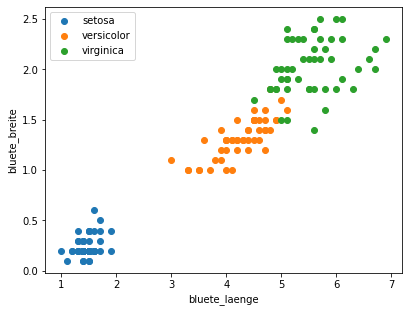

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
import matplotlib.pyplot as plt
for art in ['setosa', 'versicolor', 'virginica']:
    teil = iris[iris['art'] == art]
    plt.scatter(teil['bluete_laenge'], teil['bluete_breite'], label=art)
plt.xlabel('bluete_laenge')
plt.ylabel('bluete_breite')
plt.legend()
plt.show()
```

</details>

#### Aufgabe 1.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd

df = pd.DataFrame({'a': [1, 2, 3, 4], 'b': ['x', 'y', 'x', 'x']})
print(df.shape)
print(len(df[df['a'] > 2]))
print(df['b'].value_counts()['x'])

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(4, 2)
2
3
```

- Die Tabelle hat 4 Zeilen und 2 Spalten: `(4, 2)`.
- Nur die Zeilen mit `a` gleich 3 und 4 erfüllen `a > 2`: `2`.
- Der Wert `'x'` kommt dreimal in Spalte `b` vor: `3`.

</details>

## 2. Merkmale und Zielwerte

#### Lernen aus Beispielen

Beim **überwachten Lernen** gibt man dem Computer viele Beispiele, bei denen die richtige Antwort bekannt ist.

- Die **Merkmale** (*features*) sind die gemessenen Eigenschaften, hier z. B. die Maße einer Blüte. Man schreibt sie in eine Tabelle `X`
  (großes X, weil es mehrere Spalten sind).
- Der **Zielwert** (*target*, *label*) ist die gesuchte Antwort, hier die Art. Er steht in einer Spalte `y`.

Ist der Zielwert eine Kategorie (Art, Sorte, ja/nein), heißt die Aufgabe **Klassifikation**, die möglichen Werte heißen **Klassen**.
Ist er eine Zahl (Preis, Temperatur), heißt sie **Regression** (Notebook 3).

`y.unique()` sind die verschiedenen Werte von `y`, `sorted()` macht daraus eine sortierte Liste.

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
print(X.shape, y.shape)
print(sorted(y.unique()))
X.head(3)

#### Aufgabe 2.1

Lege für die Obst-Daten `X` (die Spalten `gewicht` und `verhaeltnis`) und `y` (die Spalte `sorte`) an und gib ihre Formen aus.

**Erwartete Ausgabe:**

```
(48, 2) (48,)
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
print(X.shape, y.shape)
```

</details>

#### Aufgabe 2.2

Gib die Klassen der Obst-Daten als sortierte Liste aus (`sorted(y.unique())`) und wie viele Klassen es sind.

**Erwartete Ausgabe:**

```
['Apfel', 'Birne']
2
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
y = obst['sorte']
print(sorted(y.unique()))
print(len(y.unique()))
```

</details>

#### Aufgabe 2.3

Lege für die Iris-Daten `X` nur mit den beiden Kelchblatt-Spalten an und zeige die letzten 3 Zeilen an (`tail(3)`).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">kelch_laenge</th>
      <th style="text-align: right">kelch_breite</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">147</th>
      <td style="text-align: right">6.5</td>
      <td style="text-align: right">3.0</td>
    </tr>
    <tr>
      <th style="text-align: right">148</th>
      <td style="text-align: right">6.2</td>
      <td style="text-align: right">3.4</td>
    </tr>
    <tr>
      <th style="text-align: right">149</th>
      <td style="text-align: right">5.9</td>
      <td style="text-align: right">3.0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite']]
X.tail(3)
```

</details>

#### Aufgabe 2.4

Ist es eine Klassifikation oder eine Regression? Speichere für jede der vier Fragen den String `'Klassifikation'` oder `'Regression'` in der Liste `antworten`
und gib sie aus: (1) Ist eine E-Mail Spam? (2) Wie viel kostet eine Wohnung? (3) Welche Ziffer zeigt ein Bild? (4) Wie hoch wird morgen die Temperatur?

**Erwartete Ausgabe:**

```
['Klassifikation', 'Regression', 'Klassifikation', 'Regression']
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
antworten = ['Klassifikation', 'Regression', 'Klassifikation', 'Regression']
print(antworten)
```

</details>

#### Aufgabe 2.5

Zeichne die Obst-Daten als Streudiagramm (Gewicht auf der x-Achse, Verhältnis auf der y-Achse), Äpfel rot und Birnen grün, mit Legende
und Achsenbeschriftungen `gewicht in g` und `verhaeltnis`.

**Erwartete Ausgabe:**



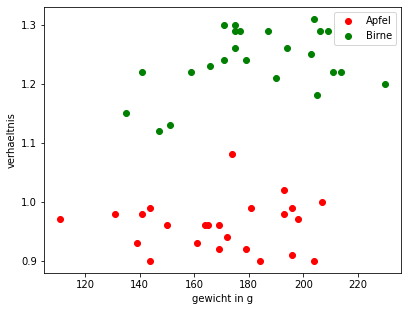

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
import matplotlib.pyplot as plt
for sorte, farbe in [('Apfel', 'red'), ('Birne', 'green')]:
    teil = obst[obst['sorte'] == sorte]
    plt.scatter(teil['gewicht'], teil['verhaeltnis'], color=farbe, label=sorte)
plt.xlabel('gewicht in g')
plt.ylabel('verhaeltnis')
plt.legend()
plt.show()
```

</details>

#### Aufgabe 2.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd

df = pd.DataFrame({'groesse': [1.6, 1.8, 1.7], 'gewicht': [55, 80, 70], 'sport': ['ja', 'nein', 'ja']})
X = df[['groesse', 'gewicht']]
y = df['sport']
print(X.shape)
print(y.shape)
print(type(X).__name__, type(y).__name__)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(3, 2)
(3,)
DataFrame Series
```

- `X` hat 3 Zeilen und 2 Spalten: `(3, 2)`.
- `y` ist eine einzelne Spalte mit 3 Werten. Die Form einer Series hat nur eine Angabe: `(3,)`.
- Mit doppelten Klammern entsteht ein `DataFrame`, mit einfachen eine `Series`.

</details>

## 3. Das erste Modell: k-nächste Nachbarn

#### Die Idee

Das Verfahren **k-nächste Nachbarn** (*k-nearest neighbors*, k-NN) ist besonders einfach: Um eine neue Blüte einzuordnen, sucht es unter allen bekannten
Blüten die `k` ähnlichsten, also die mit dem kleinsten Abstand der Merkmale. Die Art, die unter diesen `k` Nachbarn am häufigsten vorkommt, ist die Vorhersage.
Das „Lernen“ besteht hier nur darin, sich alle Beispiele zu merken.

#### Das Grundmuster: erzeugen, `fit`, `predict`

Alle Verfahren in scikit-learn werden gleich benutzt:

1. **Modell erzeugen**, mit Einstellungen in Klammern: `modell = KNeighborsClassifier(n_neighbors=3)`
2. **Trainieren** mit den Beispielen: `modell.fit(X, y)`
3. **Vorhersagen** für neue Daten: `modell.predict(X_neu)`. Das Ergebnis ist ein Array mit einer Vorhersage pro Zeile.

Die neuen Daten müssen eine Tabelle mit **denselben Spalten** wie `X` sein, auch wenn es nur eine Zeile ist.
`modell.classes_` enthält die Klassen, die das Modell kennt.

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']

modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X, y)
neu = pd.DataFrame({'bluete_laenge': [1.5, 4.8, 6.0], 'bluete_breite': [0.3, 1.6, 2.2]})
print(modell.predict(neu))
print(modell.classes_)

#### Die Nachbarn ansehen und die Treffer zählen

- `modell.kneighbors(neu)` gibt zwei Arrays zurück: die Abstände zu den `k` nächsten Nachbarn und deren Zeilennummern in `X`.
- `modell.score(X, y)` sagt alle Zeilen von `X` vorher und gibt den Anteil der richtigen Vorhersagen zurück, die **Genauigkeit** (*accuracy*).

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']

modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X, y)
neu = pd.DataFrame({'bluete_laenge': [4.87], 'bluete_breite': [1.58]})
abstaende, zeilen = modell.kneighbors(neu)
print(abstaende.round(3))
print(y.iloc[zeilen[0]].tolist())
print(f'{modell.score(X, y):.3f}')

#### Aufgabe 3.1

Trainiere ein k-NN-Modell mit `n_neighbors=3` auf den Obst-Daten (Merkmale `gewicht` und `verhaeltnis`) und sage die Sorte einer Frucht mit 180 g
und dem Verhältnis 1.2 voraus.

**Erwartete Ausgabe:**

```
['Apfel']
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X, y)
neu = pd.DataFrame({'gewicht': [180], 'verhaeltnis': [1.2]})
print(modell.predict(neu))
```

</details>

#### Aufgabe 3.2

Sage mit dem Iris-Modell aus dem Beispiel (Blütenblattlänge und -breite, `k = 3`) die Arten von vier neuen Blüten auf einmal voraus:
(1.4 | 0.2), (4.0 | 1.2), (5.5 | 2.0) und (4.9 | 1.7).

**Erwartete Ausgabe:**

```
['setosa' 'versicolor' 'virginica' 'virginica']
```

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X, y)
neu = pd.DataFrame({'bluete_laenge': [1.4, 4.0, 5.5, 4.9], 'bluete_breite': [0.2, 1.2, 2.0, 1.7]})
print(modell.predict(neu))
```

</details>

#### Aufgabe 3.3

Trainiere das Iris-Modell mit `k = 1`, `k = 5` und `k = 15` und sage jeweils die Art der Blüte (4.87 | 1.58) voraus.
Gib `k` und die Vorhersage aus. (`modell.predict(neu)[0]` ist die erste und hier einzige Vorhersage.)

**Erwartete Ausgabe:**

```
1 versicolor
5 versicolor
15 versicolor
```

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
neu = pd.DataFrame({'bluete_laenge': [4.87], 'bluete_breite': [1.58]})
for k in [1, 5, 15]:
    modell = KNeighborsClassifier(n_neighbors=k)
    modell.fit(X, y)
    print(k, modell.predict(neu)[0])
```

</details>

#### Aufgabe 3.4

Gib für die Blüte (4.87 | 1.58) die Arten ihrer 5 nächsten Nachbarn und die Abstände (3 Nachkommastellen) aus.

**Erwartete Ausgabe:**

```
['versicolor', 'versicolor', 'virginica', 'versicolor', 'versicolor']
[[0.085 0.085 0.153 0.171 0.177]]
```

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X, y)
neu = pd.DataFrame({'bluete_laenge': [4.87], 'bluete_breite': [1.58]})
abstaende, zeilen = modell.kneighbors(neu)
print(y.iloc[zeilen[0]].tolist())
print(abstaende.round(3))
```

</details>

#### Aufgabe 3.5

Gib die Genauigkeit des Obst-Modells (`k = 3`) auf den eigenen Trainingsdaten aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.771
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X, y)
print(f'{modell.score(X, y):.3f}')
```

</details>

#### Aufgabe 3.6

Trainiere ein k-NN-Modell (`k = 5`) auf allen vier Iris-Maßen und sage die Art einer Blüte mit den Maßen 6.1, 2.8, 4.7, 1.2 voraus
(in der Reihenfolge der Spalten). Gib auch die Klassen des Modells aus.

**Erwartete Ausgabe:**

```
['versicolor']
['setosa' 'versicolor' 'virginica']
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.neighbors import KNeighborsClassifier
spalten = ['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']
X = iris[spalten]
y = iris['art']
modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X, y)
neu = pd.DataFrame([[6.1, 2.8, 4.7, 1.2]], columns=spalten)
print(modell.predict(neu))
print(modell.classes_)
```

</details>

#### Aufgabe 3.7

Gib für die Iris-Daten (Blütenblattlänge und -breite) die Genauigkeit auf den Trainingsdaten für `k` = 1, 3, 5, 10, 25, 50 und 100 aus
(3 Nachkommastellen). Mit `k = 1` ist jede Blüte ihr eigener nächster Nachbar.

**Erwartete Ausgabe:**

```
1 0.987
3 0.980
5 0.960
10 0.960
25 0.967
50 0.953
100 0.660
```

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
for k in [1, 3, 5, 10, 25, 50, 100]:
    modell = KNeighborsClassifier(n_neighbors=k)
    modell.fit(X, y)
    print(f'{k} {modell.score(X, y):.3f}')
```

</details>

#### Aufgabe 3.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({'x': [1, 2, 3, 10, 11, 12]})
y = pd.Series(['A', 'A', 'A', 'B', 'B', 'B'])
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X, y)
print(modell.predict(pd.DataFrame({'x': [0, 4, 9, 20]})))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
['A' 'A' 'B' 'B']
```

Die nächsten 3 Nachbarn:
- von 0 und von 4 sind 1, 2, 3, alle `A`,
- von 9 sind 10, 11, 12, alle `B` (die 3 ist weiter weg als die 12),
- von 20 sind 10, 11, 12, alle `B`.

Ausgabe: `['A' 'A' 'B' 'B']`.

</details>

#### Aufgabe 3.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({'x': [1, 2, 3, 4, 5]})
y = pd.Series(['A', 'B', 'B', 'A', 'A'])
modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X, y)
print(modell.predict(pd.DataFrame({'x': [2]})))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
['A']
```

Mit `k = 5` sind **alle** fünf Beispiele Nachbarn, egal wie weit weg. Dreimal `A` und zweimal `B`: Die Mehrheit ist `A`,
obwohl die beiden nächsten Nachbarn (bei 2 und 3) `B` sind. Ausgabe: `['A']`.

</details>

## 4. Trainings- und Testdaten

#### Auf neuen Daten prüfen

Die Genauigkeit auf den Trainingsdaten sagt wenig: Mit `k = 1` ist sie immer 1, weil jede Blüte sich selbst als nächsten Nachbarn findet.
Ein Modell soll aber **neue** Daten richtig einordnen. Deshalb hält man einen Teil der Beispiele zurück:

`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)`

- Mit `X_train`, `y_train` (**Trainingsdaten**, hier 75 %) wird trainiert.
- Mit `X_test`, `y_test` (**Testdaten**, hier 25 %) wird geprüft. Das Modell hat sie nie gesehen.
- Die Aufteilung ist zufällig. `random_state` legt den Zufall fest, sodass bei jedem Lauf dieselbe Aufteilung herauskommt.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

print(X_train.shape, X_test.shape)
modell = KNeighborsClassifier(n_neighbors=1)
modell.fit(X_train, y_train)
print(f'Training: {modell.score(X_train, y_train):.3f}')
print(f'Test:     {modell.score(X_test, y_test):.3f}')

#### Gleich viele von jeder Klasse: `stratify`

Bei einer zufälligen Aufteilung kann eine Klasse in den Testdaten zu häufig oder zu selten vorkommen. Mit `stratify=y` wird so aufgeteilt,
dass die Anteile der Klassen in beiden Teilen gleich sind wie in `y`.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
print(y_test.value_counts().sort_index())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)
print(y_test.value_counts().sort_index())

#### Aufgabe 4.1

Teile die Obst-Daten mit `test_size=0.25` und `random_state=0` auf und gib die Formen der vier Teile aus.

**Erwartete Ausgabe:**

```
(36, 2) (12, 2) (36,) (12,)
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.model_selection import train_test_split
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.model_selection import train_test_split
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
```

</details>

#### Aufgabe 4.2

Gib für die Iris-Aufteilung aus dem Beispiel die Genauigkeit auf Trainings- und Testdaten für `k = 5` aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.973 0.974
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X_train, y_train)
print(f'{modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 4.3

In der Zelle werden 40 % der Iris-Blüten als Testdaten zurückgehalten. Gib die Test-Genauigkeit für `k` von 1 bis 15 aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 0.917
2 0.883
3 0.933
4 0.900
5 0.950
6 0.917
7 0.967
8 0.933
9 0.967
10 0.967
11 0.967
12 0.950
13 0.950
14 0.917
15 0.933
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
for k in range(1, 16):
    modell = KNeighborsClassifier(n_neighbors=k)
    modell.fit(X_train, y_train)
    print(f'{k} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 4.4

Die Genauigkeit hängt auch von der zufälligen Aufteilung ab. Teile die Iris-Daten mit `random_state` = 0 bis 4 auf (`test_size=0.25`)
und gib jeweils die Test-Genauigkeit für `k = 5` aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0 0.974
1 1.000
2 1.000
3 0.947
4 0.974
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
for zufall in range(5):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=zufall)
    modell = KNeighborsClassifier(n_neighbors=5)
    modell.fit(X_train, y_train)
    print(f'{zufall} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 4.5

Teile die Iris-Daten mit `test_size=0.3`, `random_state=2` und `stratify=y` auf und gib die Anzahl jeder Art in den Trainings- und in den Testdaten aus.

**Erwartete Ausgabe:**

```
art
setosa        35
versicolor    35
virginica     35
Name: count, dtype: int64
art
setosa        15
versicolor    15
virginica     15
Name: count, dtype: int64
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.model_selection import train_test_split
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.model_selection import train_test_split
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2, stratify=y)
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())
```

</details>

#### Aufgabe 4.6

Zeichne für die Aufteilung in der Zelle (40 % Testdaten) die Genauigkeit auf Trainings- und Testdaten für `k` von 1 bis 40 als zwei Linien mit Legende
(`Training`, `Test`) und der x-Achsen-Beschriftung `k`.

**Erwartete Ausgabe:**



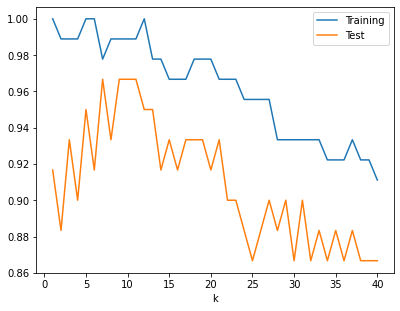

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
import matplotlib.pyplot as plt
werte_k = range(1, 41)
training = []
test = []
for k in werte_k:
    modell = KNeighborsClassifier(n_neighbors=k)
    modell.fit(X_train, y_train)
    training.append(modell.score(X_train, y_train))
    test.append(modell.score(X_test, y_test))
plt.plot(werte_k, training, label='Training')
plt.plot(werte_k, test, label='Test')
plt.xlabel('k')
plt.legend()
plt.show()
```

</details>

#### Aufgabe 4.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

X = pd.DataFrame({'x': range(20)})
y = pd.Series(['A'] * 10 + ['B'] * 10)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
print(len(X_train), len(X_test))
print(y_test.value_counts()['A'])

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
16 4
2
```

- 20 % von 20 Zeilen sind 4 Testzeilen, 16 bleiben fürs Training: `16 4`.
- Mit `stratify=y` sind die Anteile in den Testdaten wie in `y`, also halb `A`, halb `B`: `2`.

</details>

## 5. Genauigkeit und Konfusionsmatrix

#### Wo irrt sich das Modell?

Die Genauigkeit ist eine einzige Zahl. Genauer hinschauen kann man mit den Vorhersagen für die Testdaten:

- `accuracy_score(y_test, vorhersage)` aus `sklearn.metrics` berechnet die Genauigkeit wie `score()`.
- `confusion_matrix(y_test, vorhersage)` ist die **Konfusionsmatrix** (*Verwechslungsmatrix*): Zeile = richtige Klasse, Spalte = vorhergesagte Klasse.
  Auf der Diagonalen stehen die richtigen Vorhersagen, daneben die Verwechslungen. Die Klassen sind alphabetisch sortiert.

Mit einem DataFrame bekommt die Matrix lesbare Beschriftungen.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import accuracy_score, confusion_matrix

modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
print(f'{accuracy_score(y_test, vorhersage):.3f}')
matrix = confusion_matrix(y_test, vorhersage)
print(matrix)
pd.DataFrame(matrix, index=modell.classes_, columns=modell.classes_)

#### Die Fehler anzeigen und zeichnen

- `X_test[vorhersage != y_test]` wählt die Zeilen aus, die falsch eingeordnet wurden.
- `ConfusionMatrixDisplay.from_predictions(y_test, vorhersage)` zeichnet die Konfusionsmatrix als farbiges Diagramm.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
falsch = X_test[vorhersage != y_test]
print(len(falsch))
ConfusionMatrixDisplay.from_predictions(y_test, vorhersage)
plt.show()

#### Aufgabe 5.1

Trainiere ein k-NN-Modell (`k = 3`) auf den Obst-Trainingsdaten und gib die Vorhersagen für die Testdaten, die richtigen Sorten (`y_test.to_numpy()`)
und die Genauigkeit mit `accuracy_score()` aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
['Apfel' 'Apfel' 'Apfel' 'Birne' 'Apfel' 'Apfel' 'Birne' 'Apfel' 'Apfel'
 'Apfel' 'Apfel' 'Apfel']
['Apfel' 'Apfel' 'Apfel' 'Birne' 'Apfel' 'Apfel' 'Apfel' 'Apfel' 'Birne'
 'Birne' 'Birne' 'Birne']
0.583
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import accuracy_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import accuracy_score
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
print(vorhersage)
print(y_test.to_numpy())
print(f'{accuracy_score(y_test, vorhersage):.3f}')
```

</details>

#### Aufgabe 5.2

Gib für dasselbe Obst-Modell die Konfusionsmatrix als beschrifteten DataFrame aus.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">Apfel</th>
      <th style="text-align: right">Birne</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">Apfel</th>
      <td style="text-align: right">6</td>
      <td style="text-align: right">1</td>
    </tr>
    <tr>
      <th style="text-align: right">Birne</th>
      <td style="text-align: right">4</td>
      <td style="text-align: right">1</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import confusion_matrix
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import confusion_matrix
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
pd.DataFrame(confusion_matrix(y_test, vorhersage), index=modell.classes_, columns=modell.classes_)
```

</details>

#### Aufgabe 5.3

Zeige für dasselbe Obst-Modell die falsch eingeordneten Früchte an, mit einer zusätzlichen Spalte `vorhersage`. Benutze dazu
`falsch = X_test[vorhersage != y_test].copy()` und `falsch['vorhersage'] = vorhersage[vorhersage != y_test]`.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">gewicht</th>
      <th style="text-align: right">verhaeltnis</th>
      <th style="text-align: right">vorhersage</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">34</th>
      <td style="text-align: right">174</td>
      <td style="text-align: right">1.08</td>
      <td style="text-align: right">Birne</td>
    </tr>
    <tr>
      <th style="text-align: right">7</th>
      <td style="text-align: right">194</td>
      <td style="text-align: right">1.26</td>
      <td style="text-align: right">Apfel</td>
    </tr>
    <tr>
      <th style="text-align: right">10</th>
      <td style="text-align: right">141</td>
      <td style="text-align: right">1.22</td>
      <td style="text-align: right">Apfel</td>
    </tr>
    <tr>
      <th style="text-align: right">11</th>
      <td style="text-align: right">151</td>
      <td style="text-align: right">1.13</td>
      <td style="text-align: right">Apfel</td>
    </tr>
    <tr>
      <th style="text-align: right">31</th>
      <td style="text-align: right">171</td>
      <td style="text-align: right">1.30</td>
      <td style="text-align: right">Apfel</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
falsch = X_test[vorhersage != y_test].copy()
falsch['vorhersage'] = vorhersage[vorhersage != y_test]
falsch
```

</details>

#### Aufgabe 5.4

Berechne die Genauigkeit des Iris-Modells (`k = 5`, alle vier Maße) ohne `score()` und ohne `accuracy_score()`: als Mittelwert von
`vorhersage == y_test` (`True` zählt als 1). Gib sie mit 3 Nachkommastellen aus.

**Erwartete Ausgabe:**

```
0.974
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
print(f'{(vorhersage == y_test).mean():.3f}')
```

</details>

#### Aufgabe 5.5

Zeichne die Konfusionsmatrix für das Iris-Modell mit `k = 1` (alle vier Maße) mit `ConfusionMatrixDisplay.from_predictions()`.

**Erwartete Ausgabe:**



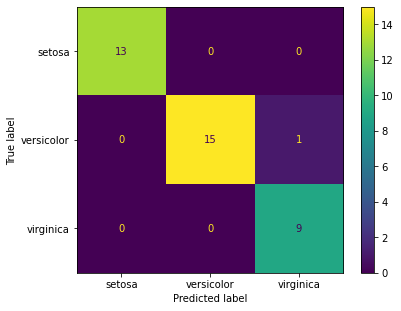

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
modell = KNeighborsClassifier(n_neighbors=1)
modell.fit(X_train, y_train)
ConfusionMatrixDisplay.from_predictions(y_test, modell.predict(X_test))
plt.show()
```

</details>

#### Aufgabe 5.6

Eine Klasse für sich: Wie viele der Testblüten jeder Art wurden richtig erkannt? Gib für jede Art die Anzahl in den Testdaten und die Anzahl
der Treffer aus (Iris, `k = 5`, alle vier Maße). Die Treffer stehen auf der Diagonalen der Konfusionsmatrix (`matrix[i, i]`), die Anzahl ist die Zeilensumme.

**Erwartete Ausgabe:**

```
setosa 13 13
versicolor 16 15
virginica 9 9
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import confusion_matrix
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.metrics import confusion_matrix
modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X_train, y_train)
matrix = confusion_matrix(y_test, modell.predict(X_test))
for i, art in enumerate(modell.classes_):
    print(art, matrix[i].sum(), matrix[i, i])
```

</details>

#### Aufgabe 5.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

richtig = ['ja', 'ja', 'nein', 'nein', 'ja']
vorhersage = ['ja', 'nein', 'nein', 'ja', 'ja']
print(accuracy_score(richtig, vorhersage))
print(confusion_matrix(richtig, vorhersage))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
0.6
[[2 1]
 [1 1]]
```

- Richtig sind die Positionen 1, 3 und 5, also 3 von 5: `0.6`.
- Die Klassen sind alphabetisch sortiert: Zeile/Spalte 0 ist `ja`, 1 ist `nein`. Von den drei echten `ja` wurden 2 als `ja` und 1 als `nein` vorhergesagt,
  von den zwei echten `nein` 1 als `ja` und 1 als `nein`: `[[2 1]` und `[1 1]]`.

</details>

## 6. Skalieren und Pipelines

#### Warum skalieren?

k-NN vergleicht Abstände. Beim Obst liegt das Gewicht zwischen etwa 110 und 230 g, das Verhältnis nur zwischen 0.9 und 1.3.
Ein Unterschied von 10 g zählt für den Abstand also viel mehr als der ganze Unterschied in der Form, obwohl gerade die Form Äpfel und Birnen trennt.

Der `StandardScaler` rechnet jedes Merkmal so um, dass es den Mittelwert 0 und die Standardabweichung 1 hat (`(x - Mittelwert) / Standardabweichung`).
Danach zählen alle Merkmale gleich viel.

- `scaler.fit(X_train)` merkt sich Mittelwerte und Standardabweichungen der **Trainingsdaten**,
- `scaler.transform(X)` rechnet damit um, `scaler.fit_transform(X_train)` macht beides auf einmal.

Wegen Rundungsfehlern kommt als Mittelwert nicht genau 0 heraus, sondern z. B. `1e-16`. Ob Zahlen fast gleich sind,
prüft `np.allclose(a, b)`.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
scaler = StandardScaler()
X_skaliert = scaler.fit_transform(X)
print(scaler.mean_.round(2))
print(X_skaliert[:3].round(2))
print(np.allclose(X_skaliert.mean(axis=0), 0), np.allclose(X_skaliert.std(axis=0), 1))

#### Pipelines

Skalieren und Modell gehören zusammen: Neue Daten müssen vor der Vorhersage genauso umgerechnet werden. Eine **Pipeline** verbindet beides zu einem Modell:
`make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))`. Bei `fit()` wird der Scaler mit den Trainingsdaten eingestellt,
bei `predict()` und `score()` werden die Daten automatisch umgerechnet.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ohne = KNeighborsClassifier(n_neighbors=3)
ohne.fit(X_train, y_train)
mit = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
mit.fit(X_train, y_train)
print(f'ohne Skalieren: {ohne.score(X_test, y_test):.3f}')
print(f'mit Skalieren:  {mit.score(X_test, y_test):.3f}')

#### Aufgabe 6.1

Skaliere die vier Iris-Maße mit dem `StandardScaler`. Gib die Mittelwerte und Standardabweichungen vor dem Skalieren aus (2 Nachkommastellen)
und prüfe mit `np.allclose()`, dass sie danach 0 und 1 sind.

**Erwartete Ausgabe:**

```
[5.84 3.06 3.76 1.2 ] [0.83 0.43 1.76 0.76]
True True
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
import numpy as np
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
import numpy as np
from sklearn.preprocessing import StandardScaler
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
X_skaliert = StandardScaler().fit_transform(X)
print(X.mean().round(2).to_numpy(), X.std(ddof=0).round(2).to_numpy())
print(np.allclose(X_skaliert.mean(axis=0), 0), np.allclose(X_skaliert.std(axis=0), 1))
```

</details>

#### Aufgabe 6.2

Rechne das Gewicht 200 g mit den Werten des Scalers von Hand um: `(200 - mean_[0]) / scale_[0]` (`scale_` sind die Standardabweichungen).
Vergleiche mit `scaler.transform()` für die Frucht (200 | 1.0). Gib beides mit 3 Nachkommastellen aus.

**Erwartete Ausgabe:**

```
0.947
[[ 0.947 -0.673]]
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.preprocessing import StandardScaler
X = obst[['gewicht', 'verhaeltnis']]
scaler = StandardScaler()
scaler.fit(X)
print(f'{(200 - scaler.mean_[0]) / scaler.scale_[0]:.3f}')
print(scaler.transform(pd.DataFrame({'gewicht': [200], 'verhaeltnis': [1.0]})).round(3))
```

</details>

#### Aufgabe 6.3

Vergleiche für die Obst-Daten die Test-Genauigkeit mit und ohne Skalieren für `k` = 1, 3, 5 und 7. Gib je Zeile `k` und beide Werte aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 0.667 1.000
3 0.583 1.000
5 0.667 1.000
7 0.583 1.000
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

obst = pd.read_csv('obst.csv')
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
for k in [1, 3, 5, 7]:
    ohne = KNeighborsClassifier(n_neighbors=k)
    ohne.fit(X_train, y_train)
    mit = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    mit.fit(X_train, y_train)
    print(f'{k} {ohne.score(X_test, y_test):.3f} {mit.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 6.4

Sage mit dem Obst-Modell mit und ohne Skalieren (`k = 3`, trainiert auf allen Obst-Daten) die Sorte einer Frucht mit 165 g und dem Verhältnis 1.25 voraus.
Die Form spricht klar für eine Birne.

**Erwartete Ausgabe:**

```
['Apfel'] ['Birne']
```

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
neu = pd.DataFrame({'gewicht': [165], 'verhaeltnis': [1.25]})
ohne = KNeighborsClassifier(n_neighbors=3)
ohne.fit(X, y)
mit = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
mit.fit(X, y)
print(ohne.predict(neu), mit.predict(neu))
```

</details>

#### Aufgabe 6.5

Ein Fehler, der oft passiert: Der Scaler wird mit **allen** Daten eingestellt, bevor aufgeteilt wird. Dann „kennt“ das Modell schon etwas von den Testdaten.
Baue für die Iris-Daten (alle vier Maße) eine Pipeline aus `StandardScaler` und k-NN (`k = 5`), trainiere sie korrekt nur mit den Trainingsdaten
und gib die Test-Genauigkeit aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.974
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modell.fit(X_train, y_train)
print(f'{modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 6.6

Zeichne die skalierten Obst-Daten als Streudiagramm (Äpfel rot, Birnen grün) mit gleichen Einheiten auf beiden Achsen (`plt.axis('equal')`).
Die skalierten Werte sind ein Array: Spalte 0 ist das Gewicht, Spalte 1 das Verhältnis.

**Erwartete Ausgabe:**



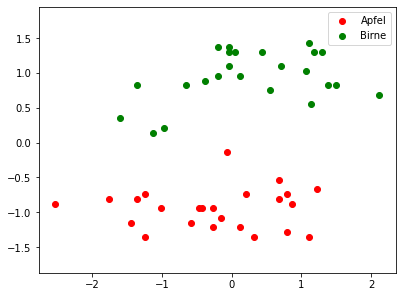

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
X_skaliert = StandardScaler().fit_transform(obst[['gewicht', 'verhaeltnis']])
for sorte, farbe in [('Apfel', 'red'), ('Birne', 'green')]:
    auswahl = (obst['sorte'] == sorte).to_numpy()
    plt.scatter(X_skaliert[auswahl, 0], X_skaliert[auswahl, 1], color=farbe, label=sorte)
plt.axis('equal')
plt.legend()
plt.show()
```

</details>

#### Aufgabe 6.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

X = np.array([[1.0], [2.0], [3.0]])
print(StandardScaler().fit_transform(X).round(3).tolist())

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[[-1.225], [0.0], [1.225]]
```

Mittelwert 2, Standardabweichung `√((1 + 0 + 1) / 3) = √(2/3) ≈ 0.816`.
`(1 - 2) / 0.816 ≈ -1.225`, `(2 - 2) / 0.816 = 0`, `(3 - 2) / 0.816 ≈ 1.225`.
Ausgabe: `[[-1.225], [0.0], [1.225]]`.

</details>

## 7. Entscheidungsgrenzen zeichnen

#### `DecisionBoundaryDisplay`

Bei zwei Merkmalen kann man zeichnen, welche Klasse das Modell an **jeder** Stelle der Ebene vorhersagen würde. Die Grenzen zwischen den Farbflächen heißen
**Entscheidungsgrenzen**. `DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)` aus `sklearn.inspection` zeichnet die Flächen
(`alpha` macht sie durchscheinend). Die Punkte zeichnet man danach mit `plt.scatter()` darüber.

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

modell = KNeighborsClassifier(n_neighbors=5)
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)
for art in modell.classes_:
    teil = X[y == art]
    plt.scatter(teil['bluete_laenge'], teil['bluete_breite'], label=art, s=15)
plt.legend()
plt.show()

#### Aufgabe 7.1

Zeichne die Entscheidungsgrenzen des Iris-Modells (Blütenblattlänge und -breite) für `k = 1` mit den Punkten darüber wie im Beispiel.
Die Grenzen sind zackig, weil jeder einzelne Punkt zählt.

**Erwartete Ausgabe:**



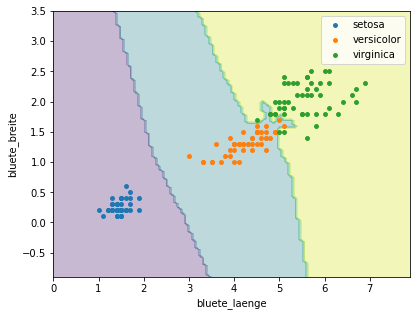

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = pd.read_csv('iris.csv')
X = iris[['bluete_laenge', 'bluete_breite']]
y = iris['art']
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
modell = KNeighborsClassifier(n_neighbors=1)
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)
for art in modell.classes_:
    teil = X[y == art]
    plt.scatter(teil['bluete_laenge'], teil['bluete_breite'], label=art, s=15)
plt.legend()
plt.show()
```

</details>

#### Aufgabe 7.2

Zeichne die Entscheidungsgrenzen des Obst-Modells (`k = 3`) **ohne** Skalieren mit den Früchten darüber (Äpfel rot, Birnen grün).
Die Grenzen verlaufen fast senkrecht: Das Modell entscheidet fast nur nach dem Gewicht.

**Erwartete Ausgabe:**



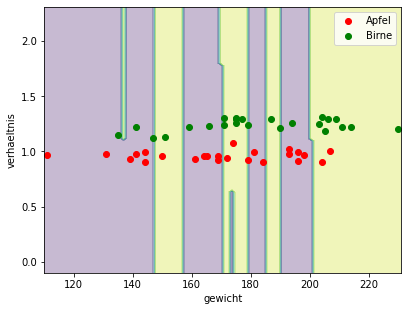

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)
for sorte, farbe in [('Apfel', 'red'), ('Birne', 'green')]:
    teil = X[y == sorte]
    plt.scatter(teil['gewicht'], teil['verhaeltnis'], color=farbe, label=sorte)
plt.legend()
plt.show()
```

</details>

#### Aufgabe 7.3

Zeichne dasselbe für die Pipeline **mit** `StandardScaler`. Jetzt verläuft die Grenze waagerecht zwischen den Formen.

**Erwartete Ausgabe:**



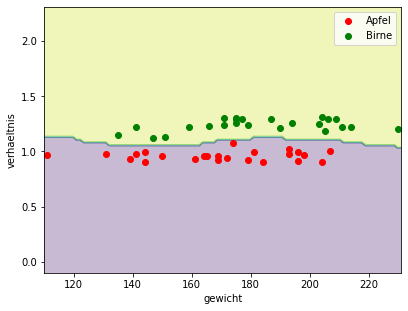

In [ ]:
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

obst = pd.read_csv('obst.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
X = obst[['gewicht', 'verhaeltnis']]
y = obst['sorte']
modell = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)
for sorte, farbe in [('Apfel', 'red'), ('Birne', 'green')]:
    teil = X[y == sorte]
    plt.scatter(teil['gewicht'], teil['verhaeltnis'], color=farbe, label=sorte)
plt.legend()
plt.show()
```

</details>

#### Aufgabe 7.4

Zeichne die Entscheidungsgrenzen für die Iris-Kelchblätter (`kelch_laenge` und `kelch_breite`) mit `k = 15` und die Blüten darüber.
Mit den Kelchblättern lassen sich *versicolor* und *virginica* schlecht trennen.

**Erwartete Ausgabe:**



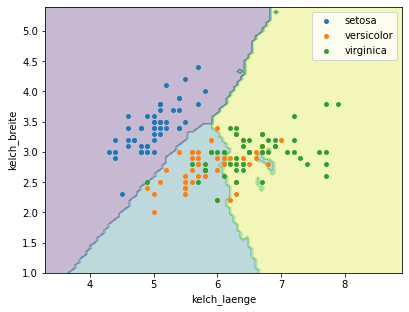

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
X = iris[['kelch_laenge', 'kelch_breite']]
y = iris['art']
modell = KNeighborsClassifier(n_neighbors=15)
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)
for art in modell.classes_:
    teil = X[y == art]
    plt.scatter(teil['kelch_laenge'], teil['kelch_breite'], label=art, s=15)
plt.legend()
plt.show()
```

</details>

## 8. Gemischte Übungen

#### Aufgabe 8.1

scikit-learn bringt weitere Datensätze mit, z. B. `load_wine`: 178 Weine aus drei Anbaugebieten (`target` 0, 1, 2) mit 13 chemischen Messwerten.
Gib die Form der Tabelle und die Anzahl der Weine je Gebiet aus und zeige die Spalten `alcohol`, `color_intensity` und `target` der ersten 3 Zeilen an.

**Erwartete Ausgabe:**

```
(178, 14)
target
0    59
1    71
2    48
Name: count, dtype: int64
```

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">alcohol</th>
      <th style="text-align: right">color_intensity</th>
      <th style="text-align: right">target</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">14.23</td>
      <td style="text-align: right">5.64</td>
      <td style="text-align: right">0</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">13.20</td>
      <td style="text-align: right">4.38</td>
      <td style="text-align: right">0</td>
    </tr>
    <tr>
      <th style="text-align: right">2</th>
      <td style="text-align: right">13.16</td>
      <td style="text-align: right">5.68</td>
      <td style="text-align: right">0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
print(wein.shape)
print(wein['target'].value_counts().sort_index())
wein[['alcohol', 'color_intensity', 'target']].head(3)
```

</details>

#### Aufgabe 8.2

Teile die Wein-Daten (alle 13 Messwerte als `X`, `target` als `y`) mit `test_size=0.25`, `random_state=0` und `stratify=y` auf. Vergleiche die
Test-Genauigkeit von k-NN (`k = 5`) ohne und mit `StandardScaler` (3 Nachkommastellen). `wein.drop(columns='target')` sind alle Spalten außer `target`.

**Erwartete Ausgabe:**

```
0.667 0.933
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X = wein.drop(columns='target')
y = wein['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
ohne = KNeighborsClassifier(n_neighbors=5)
ohne.fit(X_train, y_train)
mit = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
mit.fit(X_train, y_train)
print(f'{ohne.score(X_test, y_test):.3f} {mit.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 8.3

Warum hilft das Skalieren beim Wein so viel? Zeige die Kennzahlen `mean`, `min` und `max` der Spalten `proline`, `magnesium` und `hue` an
(`describe().loc[['mean', 'min', 'max']]`, auf 2 Nachkommastellen gerundet).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">proline</th>
      <th style="text-align: right">magnesium</th>
      <th style="text-align: right">hue</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">mean</th>
      <td style="text-align: right">746.89</td>
      <td style="text-align: right">99.74</td>
      <td style="text-align: right">0.96</td>
    </tr>
    <tr>
      <th style="text-align: right">min</th>
      <td style="text-align: right">278.00</td>
      <td style="text-align: right">70.00</td>
      <td style="text-align: right">0.48</td>
    </tr>
    <tr>
      <th style="text-align: right">max</th>
      <td style="text-align: right">1680.00</td>
      <td style="text-align: right">162.00</td>
      <td style="text-align: right">1.71</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
wein[['proline', 'magnesium', 'hue']].describe().loc[['mean', 'min', 'max']].round(2)
```

</details>

#### Aufgabe 8.4

Gib für die skalierte Wein-Pipeline die Konfusionsmatrix der Testdaten aus (Aufteilung wie oben).

**Erwartete Ausgabe:**

```
[[15  0  0]
 [ 1 15  2]
 [ 0  0 12]]
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
X = wein.drop(columns='target')
y = wein['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
modell = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modell.fit(X_train, y_train)
print(confusion_matrix(y_test, modell.predict(X_test)))
```

</details>

#### Aufgabe 8.5

Welche zwei Merkmale trennen die Weine gut? Trainiere für die Paare (`alcohol`, `proline`), (`flavanoids`, `color_intensity`) und (`ash`, `magnesium`)
jeweils eine skalierte k-NN-Pipeline (`k = 5`) auf den Trainingsdaten und gib das Paar und die Test-Genauigkeit aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
['alcohol', 'proline'] 0.800
['flavanoids', 'color_intensity'] 0.933
['ash', 'magnesium'] 0.622
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
y = wein['target']
for paar in [['alcohol', 'proline'], ['flavanoids', 'color_intensity'], ['ash', 'magnesium']]:
    X = wein[paar]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
    modell = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    modell.fit(X_train, y_train)
    print(paar, f'{modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 8.6

Zeichne die Entscheidungsgrenzen der skalierten Pipeline (`k = 5`) für die Wein-Merkmale `flavanoids` und `color_intensity`
(trainiert auf allen Weinen) mit den Weinen darüber, gefärbt nach `target` (`plt.scatter(..., c=y)`).

**Erwartete Ausgabe:**



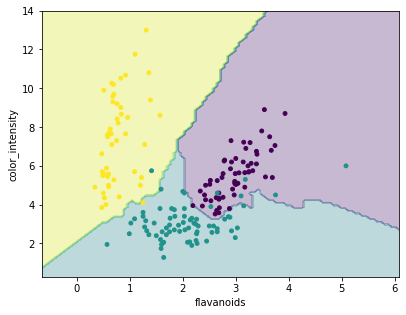

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
X = wein[['flavanoids', 'color_intensity']]
y = wein['target']
modell = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)
plt.scatter(X['flavanoids'], X['color_intensity'], c=y, s=15)
plt.show()
```

</details>

#### Aufgabe 8.7

Erstelle selbst eine kleine Tabelle mit mindestens 12 Beispielen und zwei Merkmalen (z. B. Größe und Gewicht von Hunden und Katzen) und
trainiere ein k-NN-Modell. Sage einige neue Beispiele voraus und zeichne die Entscheidungsgrenzen.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

tiere = pd.DataFrame({
    'groesse': [25, 23, 30, 28, 24, 26, 45, 60, 50, 55, 40, 65],
    'gewicht': [4.0, 3.5, 5.0, 4.5, 3.8, 4.2, 12.0, 30.0, 20.0, 25.0, 10.0, 35.0],
    'tier': ['Katze'] * 6 + ['Hund'] * 6})
X = tiere[['groesse', 'gewicht']]
y = tiere['tier']
modell = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
modell.fit(X, y)
print(modell.predict(pd.DataFrame({'groesse': [27, 42], 'gewicht': [5.5, 9.0]})))
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3)
plt.scatter(X['groesse'], X['gewicht'])
plt.show()
```

</details>